# Домашнее задание: Ансамблевые методы

### Описание
В этом задании вы примените на практике три ключевых алгоритма ансамблирования:
Для решения задания необходимо реализовать свои классы Случайного леса и IsolationForest

1.  **RandomForestClassifier** для задачи классификации и анализа устойчивости к переобучению.
2.  **RandomForestRegressor** для нетривиальной задачи восстановления пропущенных данных.
3.  **IsolationForest** для поиска аномалий в данных

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer, make_blobs
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, IsolationForest
from sklearn.metrics import accuracy_score, mean_squared_error
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import ExtraTreesRegressor
from scipy.stats import mode
# Фиксация генератора случайных чисел для воспроизводимости
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (10, 6)

## Теория: Кросс-валидация (Cross-Validation)

### Что такое кросс-валидация?

**Кросс-валидация** — это метод оценки качества модели, который более надёжен, чем простое разделение на train/test.

### Зачем она нужна?

1. **Более объективная оценка** — мы усредняем качество по нескольким разбиениям данных
2. **Эффективное использование данных** — каждый объект участвует и в обучении, и в тестировании
3. **Проверка на переобучение** — если модель работает хорошо на всех фолдах, значит, она устойчива

### Основные виды кросс-валидации

#### 1. **K-Fold Cross-Validation** (самый популярный)

```
Данные делятся на K частей (фолдов)

[ folds ]  Train  |  Test
----------|-------|-------
Fold 1:   |  2-5  |   1
Fold 2:   | 1,3-5 |   2
Fold 3:   | 1,2,4-5|  3
...
Fold K:   |  1-4  |   K

Финальная метрика = среднее по всем K фолдам
```

**Параметры:**
- `K=5` — стандартный выбор (5-fold CV)
- `K=10` — для маленьких датасетов
- `K=N` — Leave-One-Out (каждый объект — отдельный фолд)

#### 2. **Stratified K-Fold**

То же самое, но **сохраняет пропорцию классов** в каждом фолде. 
Критически важно для несбалансированных данных!

```
Данные: 90 класса 0, 10 класса 1

При K=5, обычный K-Fold может дать:
Fold 1: 20 класса 0, 0 класса 1  <- плохо!

Stratified K-Fold гарантирует:
Fold 1: 18 класса 0, 2 класса 1  <- хорошо!
```

#### 3. **ShuffleSplit**

Случайные разбиения с возможностью дублирования:
- Полезен когда нужно много случайных разбиений
- Можно контролировать размер train/test

### Как использовать в sklearn?

```python
from sklearn.model_selection import cross_val_score, KFold
from sklearn.ensemble import RandomForestClassifier

# Модель
model = RandomForestClassifier(n_estimators=100, random_state=42)

# Стратегия кросс-валидации
cv_strategy = KFold(n_splits=5, shuffle=True, random_state=42)

# Оценка качества
scores = cross_val_score(model, X, y, cv=cv_strategy, scoring='accuracy')

print(f"Scores: {scores}")
print(f"Mean: {scores.mean():.4f} (+/- {scores.std():.4f})")
```

### Метрики для кросс-валидации

- `scoring='accuracy'` — доля правильных ответов
- `scoring='f1'` — F1-score (для несбалансированных данных)
- `scoring='roc_auc'` — площадь под ROC-кривой
- `scoring='neg_mean_squared_error'` — MSE для регрессии

### Важные советы 💡

1. **Всегда используйте `shuffle=True`** — если данные упорядочены
2. **Для классификации — StratifiedKFold** — сохраняет баланс классов
3. **Сначала cross_val_score, потом test** — не подглядывайте в тест!
4. **Для Time Series** — используйте `TimeSeriesSplit` (не перемешивайте!)

### Кросс-валидация vs Простое разбиение

|                   | Train/Test Split | Cross-Validation |
|-------------------|------------------|------------------|
| **Скорость**      | ⚡ Быстро        | 🐌 Медленно      |
| **Надёжность**    | ❌ Зависит от разбиения | ✅ Усреднение |
| **Использование данных** | 60-80% | ~95% (при 5-fold) |
| **Когда применять** | Большие данные | Малые данные, важная оценка |

ПРИМЕР: Сравнение простой оценки и кросс-валидации

1. Простое разбиение (70/30):
   Accuracy на тесте: 0.9708
   ⚠️  Результат зависит от конкретного разбиения!

2. K-Fold Cross-Validation (5 folds):
   Scores по фолдам: [0.95614035 0.96491228 0.93859649 0.96491228 0.96460177]
   Mean accuracy:    0.9578 (+/- 0.0102)
   ✅ Более надёжная оценка!

3. Stratified K-Fold (5 folds):
   Scores по фолдам: [0.96491228 0.92982456 0.94736842 0.95614035 0.97345133]
   Mean accuracy:    0.9543 (+/- 0.0150)
   ✅ Лучше для несбалансированных данных!


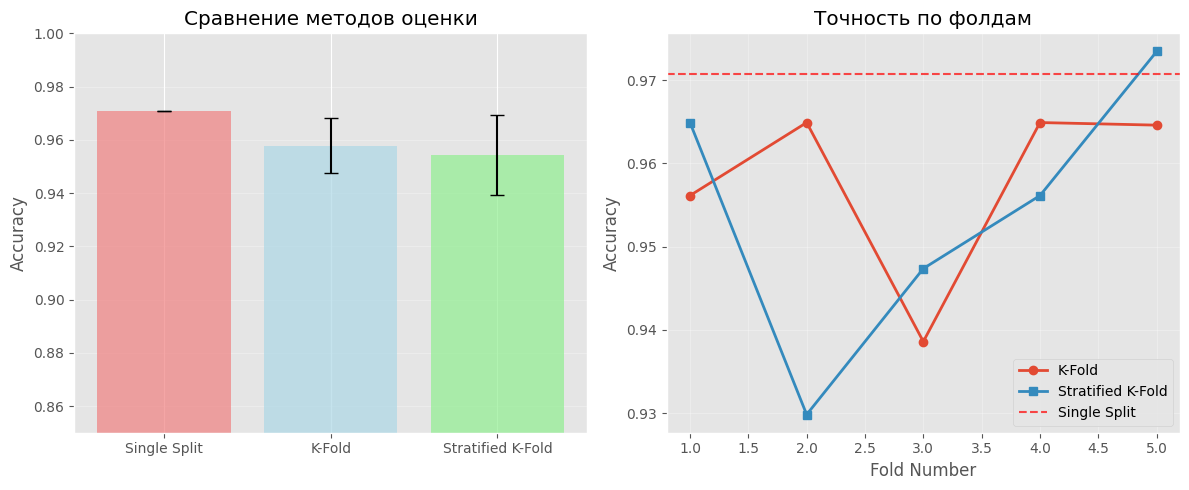


ВЫВОД:
• Кросс-валидация даёт более устойчивую оценку качества
• Стандартное отклонение показывает стабильность модели
• Stratified K-Fold предпочтительнее для классификации


In [2]:
# Практический пример: Кросс-валидация для Random Forest

from sklearn.model_selection import cross_val_score, KFold, StratifiedKFold
from sklearn.datasets import load_breast_cancer

# Загружаем данные
data = load_breast_cancer()
X, y = data.data, data.target

print("=" * 60)
print("ПРИМЕР: Сравнение простой оценки и кросс-валидации")
print("=" * 60)

# 1. Простое разбиение train/test (как в задании 1)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE
)

rf_single = RandomForestClassifier(n_estimators=50, random_state=RANDOM_STATE, n_jobs=-1)
rf_single.fit(X_train, y_train)
single_score = accuracy_score(y_test, rf_single.predict(X_test))

print(f"\n1. Простое разбиение (70/30):")
print(f"   Accuracy на тесте: {single_score:.4f}")
print(f"   ⚠️  Результат зависит от конкретного разбиения!")

# 2. K-Fold Cross-Validation
kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rf = RandomForestClassifier(n_estimators=50, random_state=RANDOM_STATE, n_jobs=-1)
kfold_scores = cross_val_score(rf, X, y, cv=kfold, scoring='accuracy')

print(f"\n2. K-Fold Cross-Validation (5 folds):")
print(f"   Scores по фолдам: {kfold_scores}")
print(f"   Mean accuracy:    {kfold_scores.mean():.4f} (+/- {kfold_scores.std():.4f})")
print(f"   ✅ Более надёжная оценка!")

# 3. Stratified K-Fold (сохраняет баланс классов)
stratified_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
stratified_scores = cross_val_score(rf, X, y, cv=stratified_kfold, scoring='accuracy')

print(f"\n3. Stratified K-Fold (5 folds):")
print(f"   Scores по фолдам: {stratified_scores}")
print(f"   Mean accuracy:    {stratified_scores.mean():.4f} (+/- {stratified_scores.std():.4f})")
print(f"   ✅ Лучше для несбалансированных данных!")

# Визуализация
plt.figure(figsize=(12, 5))

# График 1: Сравнение оценок
plt.subplot(1, 2, 1)
methods = ['Single Split', 'K-Fold', 'Stratified K-Fold']
means = [single_score, kfold_scores.mean(), stratified_scores.mean()]
stds = [0, kfold_scores.std(), stratified_scores.std()]
colors = ['lightcoral', 'lightblue', 'lightgreen']

bars = plt.bar(methods, means, yerr=stds, color=colors, capsize=5, alpha=0.7)
plt.ylabel('Accuracy')
plt.title('Сравнение методов оценки')
plt.ylim(0.85, 1.0)
plt.grid(axis='y', alpha=0.3)

# График 2: Распределение по фолдам
plt.subplot(1, 2, 2)
plt.plot(range(1, 6), kfold_scores, marker='o', label='K-Fold', linewidth=2)
plt.plot(range(1, 6), stratified_scores, marker='s', label='Stratified K-Fold', linewidth=2)
plt.axhline(single_score, color='r', linestyle='--', label='Single Split', alpha=0.7)
plt.xlabel('Fold Number')
plt.ylabel('Accuracy')
plt.title('Точность по фолдам')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\n" + "=" * 60)
print("ВЫВОД:")
print("=" * 60)
print("• Кросс-валидация даёт более устойчивую оценку качества")
print("• Стандартное отклонение показывает стабильность модели")
print("• Stratified K-Fold предпочтительнее для классификации")

###  Ваша реализация Случайного Леса для классификации

### Задача: Реализовать бэггинг (Bootstrap Aggregating) над решающими деревьями

In [3]:
class MyRandomForestClassifier:
    """
    Ваша реализация Случайного Леса для классификации.

    Задача: Реализовать бэггинг (Bootstrap Aggregating) над решающими деревьями.
    """
    def __init__(self, n_estimators=10, max_depth=None, max_features='sqrt', random_state=42):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.max_features = max_features
        self.random_state = random_state
        self.trees = [] # Сюда будем складывать обученные деревья

    def fit(self, X, y):
        """
        Обучение ансамбля.
        1. Создайте n_estimators деревьев.
        2. Для каждого дерева создайте бутстрап-выборку (X_boot, y_boot).
        3. Обучите дерево на этой выборке.
        """
        self.trees = []
        n_samples = X.shape[0]
        np.random.seed(self.random_state)

        for i in range(self.n_estimators):
            #TODO 1: Сделайте Bootstrap (выборку с возвращением).
            # Подсказка: используйте np.random.choice для генерации индексов
            indices = np.random.choice(n_samples, size=n_samples, replace=True)

            X_boot, y_boot = X[indices], y[indices]

            #TODO 2: Создайте базовую модель DecisionTreeClassifier
            # Не забудьте передать max_depth и max_features
            tree = DecisionTreeClassifier(
                max_depth=self.max_depth,
                max_features=self.max_features,
                random_state=self.random_state
            )

            #TODO 3: Обучите дерево и добавьте его в список self.trees
            tree.fit(X_boot, y_boot)
            self.trees.append(tree)

        return self

    def predict(self, X):
        """
        Предсказание классов.
        1. Получите предсказания от всех деревьев.
        2. Для каждого объекта выберите класс, за который проголосовало большинство.
        """
        # Сюда будем собирать предсказания всех деревьев: (n_samples, n_estimators)
        all_preds = np.zeros((X.shape[0], self.n_estimators))

        for i, tree in enumerate(self.trees):
            #TODO 4: Заполните столбец i предсказаниями текущего дерева
            all_preds[:, i] = tree.predict(X)

        #TODO 5: Реализуйте голосование большинства (Hard Voting)
        # Подсказка: используйте scipy.stats.mode(all_preds, axis=1)
        result = mode(all_preds, axis=1) 

        return result.mode.ravel()



###  Ваша реализация Случайного Леса для регрессии

### Принцип тот же, но агрегация через усреднение

In [4]:

class MyRandomForestRegressor:
    """
    Ваша реализация Случайного Леса для регрессии.
    Принцип тот же, но агрегация через усреднение.
    """

    def __init__(self, n_estimators=10, max_depth=None, max_features='sqrt', random_state=42):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.max_features = max_features
        self.random_state = random_state
        self.trees = []

    def fit(self, X, y):
        self.trees = []
        n_samples = X.shape[0]
        np.random.seed(self.random_state)

        for i in range(self.n_estimators):
            #TODO 1: Реализуйте Bootstrap (аналогично классификации)
            indices = np.random.choice(n_samples, size=n_samples, replace=True)
            X_boot, y_boot = X[indices], y[indices]

            #TODO 2: Используйте DecisionTreeRegressor как базовую модель
            tree = DecisionTreeRegressor(
                max_depth=self.max_depth,
                max_features=self.max_features,
                random_state=self.random_state
            )

            #TODO 3: Обучите и сохраните
            tree.fit(X_boot, y_boot)
            self.trees.append(tree)

        return self

    def predict(self, X):
        """
        Предсказание значений.
        Агрегация: Среднее арифметическое предсказаний всех деревьев.
        """
        # Массив для сбора ответов
        all_preds = np.zeros((X.shape[0], self.n_estimators))

        for i, tree in enumerate(self.trees):
            #TODO 4: Получите предсказания дерева
            all_preds[:, i] = tree.predict(X)

        #TODO 5: Посчитайте среднее по строкам (axis=1)
        mean_preds = np.mean(all_preds, axis=1) 

        return mean_preds

###  Упрощенная версия Isolation Forest

### Мы строим случайные деревья (ExtraTrees).

Аномалии - это точки, которые попадают в листья на маленькой глубине (их легко изолировать)

In [5]:
from sklearn.tree import ExtraTreeRegressor
class MySimplifiedIsolationForest:
    """
    Упрощенная версия Isolation Forest.
    Идея: Мы строим случайные деревья (ExtraTrees)
    Аномалии — это точки, которые попадают в листья на маленькой глубине (их легко изолировать)
    """

    def __init__(self, n_estimators=10, max_samples=100, random_state=42):
        self.n_estimators = n_estimators
        self.max_samples = max_samples # Размер подвыборки для каждого дерева
        self.random_state = random_state
        self.trees = []

    def fit(self, X):
        """
        В Isolation Forest мы не используем y (обучение без учителя).
        """
        self.trees = []
        n_samples = X.shape[0]
        np.random.seed(self.random_state)

        for i in range(self.n_estimators):
            #TODO 1: Выберите случайные max_samples индексов (без возвращения для разнообразия)
            replace_flag = self.max_samples > n_samples
            indices = np.random.choice(n_samples, size=self.max_samples, replace=replace_flag)
            X_sub = X[indices]

            # Используем ExtraTreeRegressor, который делает случайные сплиты
            # Мы будем "предсказывать" просто случайные значения, нам важна только структура дерева
            tree = ExtraTreeRegressor(max_depth=None, max_features=1)

            # Фиктивный y, он не важен для построения структуры в данном упрощении
            tree.fit(X_sub, np.zeros(len(X_sub)))

            self.trees.append(tree)
        return self

    def decision_function(self, X):
        """
        Возвращает меру аномальности.
        В реальном IF это длина пути. Здесь мы будем аппроксимировать это через
        глубину листа, в который попал объект.
        Чем меньше глубина -> тем проще изолировать -> тем больше это аномалия.
        """
        depths = np.zeros((X.shape[0], self.n_estimators))

        for i, tree in enumerate(self.trees):
            # apply возвращает индекс листа, в который попал объект
            leaf_indices = tree.apply(X)

            #TODO 2: Для каждого объекта нужно узнать глубину этого листа

            # В sklearn глубина хранится в tree.tree_.n_node_samples или можно вычислить
            # Для упрощения задачи: можно использовать decision_path
            node_indicator = tree.decision_path(X)


            # Сумма единиц в строке матрицы путей = глубина листа
            depths[:, i] = np.array(node_indicator.getnnz(axis=1))

        # Усредняем глубину по всем деревьям
        avg_depth = depths.mean(axis=1)

        # Инвертируем: чем меньше глубина, тем выше score (аномалия)
        # Это упрощенная формула, не совсем как в оригинальной статье, но передает суть
        score = -avg_depth
        return score

    def predict(self, X, threshold=-10):
        """
        Возвращает -1 для аномалий и 1 для нормы.
        """
        scores = self.decision_function(X)
        #TODO 3: Если score > threshold -> Аномалия (-1), иначе Норма (1)
        # В реальном if порог определяется через contamination
        predictions = np.ones(X.shape[0])
        predictions[scores > threshold] = -1
        return predictions

## Задание 1. Классификация: Лес против Дерева

Цель: Экспериментально подтвердить, что увеличение количества деревьев в лесу не приводит к переобучению и повышает стабильность.

Используется датасет Breast Cancer (бинарная классификация рака груди)

In [6]:
# 1. Загрузка данных
data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE)

# 2. Обучение одиночного дерева (baseline)
dt = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt.fit(X_train, y_train)
dt_acc = accuracy_score(y_test, dt.predict(X_test))

print(f"Точность одиночного дерева: {dt_acc:.4f}")

Точность одиночного дерева: 0.9415


In [7]:
# 3. Эксперимент с количеством деревьев
# Задача: Обучить RandomForestClassifier в цикле с n_estimators от 1 до 100
# Сохранить accuracy на тестовой выборке в список rf_scores

n_estimators_list = range(1, 101)
rf_scores = []

for n in n_estimators_list:
    #TODO: инициализируйте и обучите RandomForestClassifier
    # Используйте random_state=RANDOM_STATE и n_jobs=-1 для ускорения
    rf = RandomForestClassifier(n_estimators=n, random_state=RANDOM_STATE)
    rf.fit(X_train, y_train)
    #TODO: получите accuracy на тестовой выборке
    acc = accuracy_score(y_test, rf.predict(X_test))
    rf_scores.append(acc)


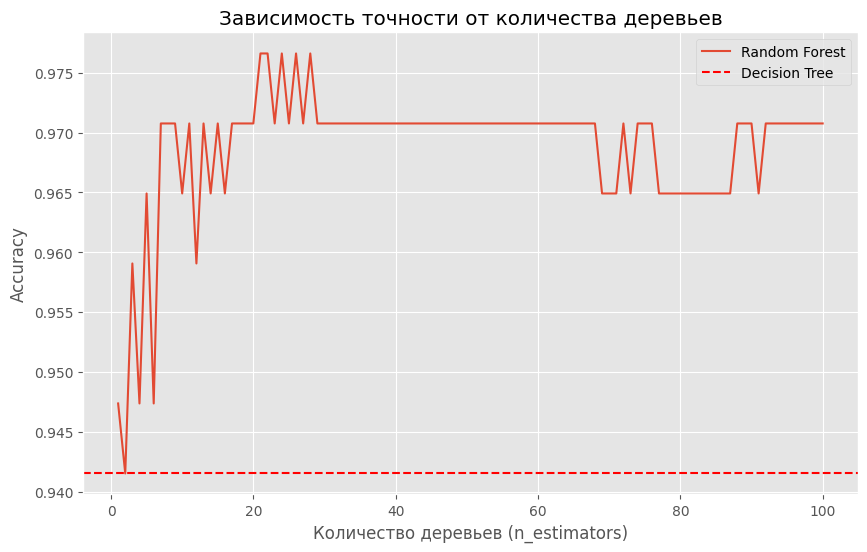

In [8]:
# Визуализация
plt.plot(n_estimators_list, rf_scores, label='Random Forest')
plt.axhline(dt_acc, color='r', linestyle='--', label='Decision Tree')
plt.xlabel('Количество деревьев (n_estimators)')
plt.ylabel('Accuracy')
plt.title('Зависимость точности от количества деревьев')
plt.legend()
plt.show()

In [9]:
# ТЕСТЫ ДЛЯ ЗАДАНИЯ 1
assert len(rf_scores) == 100, "Список rf_scores должен содержать 100 значений"
assert rf_scores[-1] > dt_acc, "В данном случае Лес должен работать лучше одиночного дерева"

## Задание 2. Инженерное применение: Импутация данных

Цель: Использовать регрессионный лес для восстановления пропущенных значений

Мы намеренно удалим часть данных и попробуем их восстановить

In [10]:
# Подготовка данных
# Генерируем данные, где признаки коррелируют друг с другом
X_gen, y_gen = make_blobs(n_samples=1000, centers=1, n_features=5, random_state=RANDOM_STATE)
df = pd.DataFrame(X_gen, columns=[f'Feat_{i}' for i in range(5)])

# Искусственно создаем пропуски в колонке Feat_0
n_missing = 200
missing_indices = np.random.choice(df.index, n_missing, replace=False)

# Сохраняем истинные значения для проверки
true_values = df.loc[missing_indices, 'Feat_0'].copy()

# Удаляем значения
df.loc[missing_indices, 'Feat_0'] = np.nan
print(f"Количество пропусков: {df['Feat_0'].isna().sum()}")

Количество пропусков: 200


In [11]:
# Реализация восстановления

# 1. Разделите датафрейм df на две части:
# train_df: строки, где Feat_0 НЕ пустой
# predict_df: строки, где Feat_0 пустой (NaN)

#TODO
train_df = df[df['Feat_0'].notna()]
predict_df = df[df['Feat_0'].isna()]

# 2. Сформируйте признаки (X) и целевую переменную (y)
# X: все колонки, кроме Feat_0
# y: колонка Feat_0

#TODO
X_train_imp = train_df.drop(columns=['Feat_0'])
y_train_imp = train_df['Feat_0']
X_predict_imp = predict_df.drop(columns=['Feat_0'])

# 3. Обучите RandomForestRegressor
#TODO
rf_imputer = RandomForestRegressor(n_estimators=100, max_depth=3, random_state=42)
rf_imputer.fit(X_train_imp, y_train_imp)

# 4. Предскажите пропущенные значения
#TODO
predicted_values = rf_imputer.predict(X_predict_imp)

# Сравнение с простым заполнением средним
#TODO
mean_fill_values = np.full(len(true_values), y_train_imp.mean())

mse_rf = mean_squared_error(true_values, predicted_values)
mse_mean = mean_squared_error(true_values, mean_fill_values)

#TODO: выведите обе метрики

print(f"MSE (Random Forest): {mse_rf:.4f}")
print(f"MSE (Заполнение средним): {mse_mean:.4f}")


MSE (Random Forest): 0.9680
MSE (Заполнение средним): 0.9431


In [12]:
# ТЕСТЫ ДЛЯ ЗАДАНИЯ 2
assert len(train_df) == 800, "Размер обучающей выборки неверен"
assert len(predict_df) == 200, "Размер выборки для предсказания неверен"
assert mse_rf > mse_mean, "Модель должна работать лучше, чем заполнение средним"
print("Тест пройден: Импутация выполнена успешно.")

Тест пройден: Импутация выполнена успешно.


## Задание 3. Поиск аномалий

**Цель:** Найти выбросы в данных, используя `IsolationForest`

In [13]:
# Генерация данных
# 300 нормальных точек и 20 аномалий
X_normal, _ = make_blobs(n_samples=300, centers=1, cluster_std=1.0, center_box=(0, 0), random_state=RANDOM_STATE)
X_anomalies = np.random.uniform(low=-10, high=10, size=(20, 2))
X_final = np.vstack([X_normal, X_anomalies])

In [ ]:
#TODO:
# 1. Инициализируйте IsolationForest. Установите contamination=0.06 (примерная доля выбросов)
iso_forest = IsolationForest(contamination=0.06)

# 2. Обучите модель и получите предсказания (fit_predict)
# Результат должен содержать: 1 (норма) и -1 (аномалия)
preds = iso_forest.fit_predict(X_final)


TypeError: float() argument must be a string or a real number, not 'ellipsis'

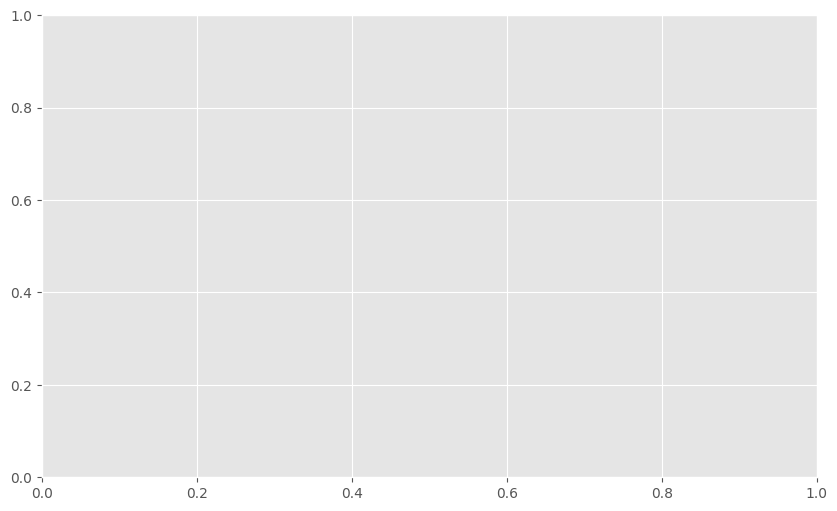

In [15]:

# Визуализация
plt.scatter(X_final[:, 0], X_final[:, 1], c=preds, cmap='coolwarm', edgecolor='k')
plt.title('Isolation Forest Detection')
plt.show()

In [ ]:
# ТЕСТЫ ДЛЯ ЗАДАНИЯ 3
n_detected_anomalies = np.sum(preds == -1)
print(f"Обнаружено аномалий: {n_detected_anomalies}")

# Проверяем, что модель нашла хотя бы часть аномалий (мы знаем, что их 20)
assert 15 <= n_detected_anomalies <= 25, "Количество найденных аномалий должно быть близко к истинному (20)"